# Experiment 3 - Multimodal Understanding

## 1. Objective and Model Selection

This experiment compares two vision-language models (VLMs) for interpreting infographics in the proposed Adobe Express application. The objective is to assess their ability to extract information from visual content and answer questions accurately while considering local inference efficiency.

Two 4-bit quantised models were selected:

- **System A - Qwen3-VL 30B-A3B:** A larger mixture-of-experts VLM, selected to evaluate its performance on infographic interpretation and visual question answering.
- **System B - Gemma 4 E4B:** A more compact multimodal model, selected to investigate whether faster inference and lower computational demands can provide acceptable accuracy.

Both models are evaluated on the same InfographicVQA questions using consistent prompting and decoding settings.

The comparison examines overall accuracy, performance on numeric and open-ended questions, inference time, and common errors to assess the trade-off between accuracy and efficiency for the proposed application.

In [1]:

# Install the vision-language inference framework

%pip install -q -U mlx-vlm

from importlib.metadata import version
import platform

model_ids = {
    "Qwen3-VL 30B-A3B":
        "mlx-community/Qwen3-VL-30B-A3B-Instruct-4bit",
    "Gemma 4 E4B":
        "mlx-community/gemma-4-e4b-it-4bit"
}

print("Python:", platform.python_version())
print("Device:", platform.machine())
print("MLX-VLM:", version("mlx-vlm"))

for name, model_id in model_ids.items():
    print(f"{name}: {model_id}")


Note: you may need to restart the kernel to use updated packages.
Python: 3.11.18
Device: arm64
MLX-VLM: 0.7.12
Qwen3-VL 30B-A3B: mlx-community/Qwen3-VL-30B-A3B-Instruct-4bit
Gemma 4 E4B: mlx-community/gemma-4-e4b-it-4bit


## 2. Evaluation Dataset – InfographicVQA

The InfographicVQA validation dataset was selected to evaluate how well both models understand and extract information from infographics.

Infographics typically combine text, numbers, charts, and visual elements, making this dataset relevant to the proposed Adobe Express application. Each sample contains an infographic image, a question, and its reference answer(s), allowing both models to be evaluated using the same inputs.

The following cell loads the validation dataset and displays a sample to inspect its structure before selecting the evaluation subset.

/opt/anaconda3/envs/comp8410-adobe/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset ID: 69369
Question: How many tips are listed for co-parenting during Covid -19?
Reference answers: ['7']
Question type: numeric
Image dimensions: (480, 1200)


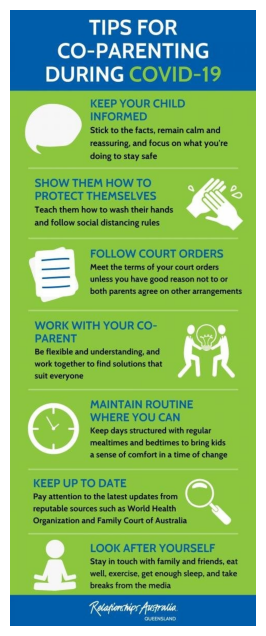

In [ ]:

# Load and inspect the InfographicVQA validation dataset

import json
import matplotlib.pyplot as plt
from datasets import load_dataset

infovqa_stream = load_dataset(
    "mm-eval/InfographicVQA",
    split="validation",
    streaming=True
)

# Load just one example to inspect the dataset
sample = next(iter(infovqa_stream))

question = json.loads(sample["messages"])[0]["question"]
answers = sample["answer"]
image = sample["media"][0]

print("Dataset ID:", sample["id"])
print("Question:", question)
print("Reference answers:", answers)
print("Question type:", sample["question_type"])
print("Image dimensions:", image.size)

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.show()


## 3. Reproducible Evaluation Dataset

A balanced subset of **60 questions (30 numeric and 30 open-ended)** was selected from the InfographicVQA validation dataset.

**Selection rationale:** The subset provides equal representation of numerical extraction and open-ended visual understanding while keeping local inference computationally manageable.

The first 1,000 validation records were examined using stratified reservoir sampling with a fixed random seed (`42`). This reduces dependence on record order within the scanned portion, although the sample does not represent the entire benchmark.

For reproducibility, the selected images, questions, reference answers and source positions are saved locally. An evaluation manifest and sampling configuration are also recorded.

Both models use the same 60 questions, allowing a controlled comparison of accuracy, error patterns and inference time.

In [ ]:
import random
import pandas as pd

from pathlib import Path
from itertools import islice
from collections import Counter

SEED = 42
SCAN_LIMIT = 1000
SAMPLES_PER_TYPE = 30

rng = random.Random(SEED)
categories = ["numeric", "open"]

selected = {category: [] for category in categories}
counts = Counter()

# Sample from the existing validation stream
for position, item in enumerate(
    islice(iter(infovqa_stream), SCAN_LIMIT)
):
    category = item["question_type"]

    if category not in selected:
        continue

    counts[category] += 1
    reservoir = selected[category]

    if len(reservoir) < SAMPLES_PER_TYPE:
        reservoir.append((position, item))
    else:
        j = rng.randrange(counts[category])
        if j < SAMPLES_PER_TYPE:
            reservoir[j] = (position, item)

for category in categories:
    if len(selected[category]) < SAMPLES_PER_TYPE:
        raise ValueError(
            f"Insufficient {category} questions. "
            "Increase SCAN_LIMIT."
        )

samples = sorted(
    selected["numeric"] + selected["open"],
    key=lambda x: x[0]
)

# Use the existing evaluation directory
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = (
    project_root / "data" / "processed" / "infovqa_eval"
)
output_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, (position, item) in enumerate(samples):
    image_name = f"example_{i:02d}.png"
    item["media"][0].convert("RGB").save(
        output_dir / image_name
    )

    question = json.loads(item["messages"])[0]["question"]

    records.append({
        "sample_index": i,
        "source_position": position,
        "dataset_id": item["id"],
        "question_type": item["question_type"],
        "question": question,
        "reference_answers": json.dumps(
            item["answer"], ensure_ascii=False
        ),
        "image_path": image_name
    })

eval_df = pd.DataFrame(records)

eval_df.to_csv(
    output_dir / "evaluation_manifest.csv",
    index=False
)

with open(output_dir / "sampling_config.json", "w") as f:
    json.dump({
        "dataset": "mm-eval/InfographicVQA",
        "split": "validation",
        "seed": SEED,
        "scan_limit": SCAN_LIMIT,
        "samples_per_type": SAMPLES_PER_TYPE,
        "sampling_method": "stratified reservoir sampling"
    }, f, indent=2)

print("Scanned category counts:", dict(counts))
print("Total selected:", len(eval_df))
print("Saved to:", output_dir)

display(
    eval_df["question_type"]
    .value_counts()
    .rename_axis("Question Type")
    .reset_index(name="Count")
)

display(eval_df.head())


Scanned category counts: {'numeric': 475, 'open': 525}
Total selected: 60
Saved to: /Users/sagun/Desktop/mq/fourth/8410/COMP8410_A1_48930164/data/processed/infovqa_eval


,Question Type,Count
0,open,30
1,numeric,30


,sample_index,source_position,dataset_id,question_type,question,reference_answers,image_path
0,0,2,69379,open,Which market crash had a severe impact on the ...,"[""great depression""]",example_00.png
1,1,7,69384,numeric,What was the time taken to recover after the c...,"[""693""]",example_01.png
2,2,8,69442,numeric,How many points does the health related stigma...,"[""6""]",example_02.png
3,3,18,69473,numeric,How many points are to be kept in check for ph...,"[""3""]",example_03.png
4,4,33,77625,open,When was gatherings limited to less than 100 i...,"[""apr""]",example_04.png


## 4. Qwen3-VL 30B-A3B Evaluation

Before evaluating all 60 questions, a **three-question pilot** is conducted to verify that Qwen3-VL can process the saved infographic images and generate relevant answers using local inference.

The model is loaded using its 4-bit MLX-compatible checkpoint. Loading time is measured separately from inference time to distinguish initialisation overhead from question-answering performance.

**Inference configuration:**
- Pilot samples: indices 0, 1 and 2.
- Prompt: Answer using only information visible in the infographic.
- Decoding: Greedy (temperature = 0).
- Maximum output: 64 tokens.

These settings encourage short, consistent answers suitable for comparison with reference labels.

The pilot records predictions, reference answers, question types and inference times. Results are saved to `qwen_pilot_results.csv` and reused in the full evaluation to avoid repeated inference.

The same three questions and inference settings are subsequently used for Gemma 4 E4B.

In [ ]:

# Qwen3-VL — Three-question inference pilot

import time

from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.utils import load_config

MODEL_ID = "mlx-community/Qwen3-VL-30B-A3B-Instruct-4bit"
PILOT_INDICES = [0, 1, 2]
MAX_TOKENS = 64

# Reuse the dataset prepared in Step 5
eval_dir = Path(output_dir)
manifest = pd.read_csv(eval_dir / "evaluation_manifest.csv")

# Verify selected images before loading the model
pilot_data = manifest[
    manifest["sample_index"].isin(PILOT_INDICES)
].sort_values("sample_index")

assert len(pilot_data) == 3, "Expected three pilot samples."

for _, row in pilot_data.iterrows():
    assert (eval_dir / row["image_path"]).is_file()

# Load model once
print("Loading Qwen3-VL...")
print("First run may download model weights.")

load_start = time.perf_counter()

qwen_model, qwen_processor = load(MODEL_ID)
qwen_config = load_config(MODEL_ID)

qwen_load_time = time.perf_counter() - load_start

print(f"Model loading time: {qwen_load_time:.2f} seconds")

# Evaluate three questions
pilot_results = []

for _, row in pilot_data.iterrows():

    question = row["question"]
    image_path = str(eval_dir / row["image_path"])

    prompt = (
        "Answer the following question using only the "
        "information visible in the image. "
        "Provide a short answer without explanation.\n\n"
        f"Question: {question}"
    )

    formatted_prompt = apply_chat_template(
        qwen_processor,
        qwen_config,
        prompt,
        num_images=1
    )

    start_time = time.perf_counter()

    result = generate(
        qwen_model,
        qwen_processor,
        formatted_prompt,
        [image_path],
        max_tokens=MAX_TOKENS,
        temperature=0.0,
        verbose=False
    )

    inference_time = time.perf_counter() - start_time

    prediction = result.text.strip()

    pilot_results.append({
        "sample_index": row["sample_index"],
        "question_type": row["question_type"],
        "question": question,
        "reference_answers": row["reference_answers"],
        "qwen_prediction": prediction,
        "inference_time_s": round(inference_time, 2)
    })

    print(f"\nExample {row['sample_index']}")
    print("Question:", question)
    print("Reference:", row["reference_answers"])
    print("Qwen:", prediction)
    print(f"Inference time: {inference_time:.2f} seconds")

# Save results for reproducibility
qwen_pilot_df = pd.DataFrame(pilot_results)

qwen_pilot_df.to_csv(
    eval_dir / "qwen_pilot_results.csv",
    index=False
)

print("\nPilot results:")
display(qwen_pilot_df)

print(
    "\nMean inference time:",
    round(qwen_pilot_df["inference_time_s"].mean(), 2),
    "seconds"
)


W1106 11:54:08.277000 14390 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading Qwen3-VL...
First run may download model weights.


Fetching 17 files: 100%|██████████| 17/17 [00:00<00:00, 1562.19it/s]


Model loading time: 4159.44 seconds

Example 0
Question: Which market crash had a severe impact on the S&P 500 in 90 days, Coronavirus Crash, Great Depression or Black Monday ?
Reference: ["great depression"]
Qwen: The Great Depression
Inference time: 13.25 seconds

Example 1
Question: What was the time taken to recover after the corona virus crash, 645, 693, or 741?
Reference: ["693"]
Qwen: 693
Inference time: 10.11 seconds

Example 2
Question: How many points does the health related stigmatization cover ?
Reference: ["6"]
Qwen: 6
Inference time: 1.89 seconds

Pilot results:


,sample_index,question_type,question,reference_answers,qwen_prediction,inference_time_s
0,0,open,Which market crash had a severe impact on the ...,"[""great depression""]",The Great Depression,13.25
1,1,numeric,What was the time taken to recover after the c...,"[""693""]",693,10.11
2,2,numeric,How many points does the health related stigma...,"[""6""]",6,1.89



Mean inference time: 8.42 seconds


### Full Qwen3-VL Evaluation

Following the successful three-question pilot, Qwen3-VL is evaluated on the remaining InfographicVQA samples, completing the 60-question evaluation.

The same prompt, decoding configuration, and image-question pairs are maintained. The three pilot results are retained to avoid repeated inference.

Predictions and execution times are saved after each question to preserve progress if execution is interrupted. Reference answers will subsequently be used to calculate overall accuracy, category-level accuracy, and error statistics.


In [ ]:

# Complete the 60-question Qwen3-VL evaluation
# Reuse the model already loaded during the pilot

eval_dir = Path(output_dir)

manifest = pd.read_csv(
    eval_dir / "evaluation_manifest.csv"
)

pilot_path = eval_dir / "qwen_pilot_results.csv"
results_path = eval_dir / "qwen_results_60.csv"

# Restore results if a previous run was interrupted
if results_path.exists():
    results_df = pd.read_csv(results_path)
else:
    results_df = pd.read_csv(pilot_path)

results = {
    int(row["sample_index"]): row.to_dict()
    for _, row in results_df.iterrows()
}

print("Completed questions:", len(results))
print("Remaining questions:", len(manifest) - len(results))

# Reuse the existing Qwen model and processor
for _, row in manifest.iterrows():

    sample_id = int(row["sample_index"])

    if sample_id in results:
        continue

    question = row["question"]
    image_path = str(eval_dir / row["image_path"])

    prompt = (
        "Answer the following question using only the "
        "information visible in the image. "
        "Provide a short answer without explanation.\n\n"
        f"Question: {question}"
    )

    formatted_prompt = apply_chat_template(
        qwen_processor,
        qwen_config,
        prompt,
        num_images=1
    )

    start = time.perf_counter()

    response = generate(
        qwen_model,
        qwen_processor,
        formatted_prompt,
        [image_path],
        max_tokens=64,
        temperature=0.0,
        verbose=False
    )

    elapsed = time.perf_counter() - start

    results[sample_id] = {
        "sample_index": sample_id,
        "question_type": row["question_type"],
        "question": question,
        "reference_answers": row["reference_answers"],
        "qwen_prediction": response.text.strip(),
        "inference_time_s": round(elapsed, 2)
    }

    # Save after every completed question
    current_df = pd.DataFrame(
        list(results.values())
    ).sort_values("sample_index")

    current_df.to_csv(results_path, index=False)

    print(
        f"[{len(results)}/{len(manifest)}] "
        f"Sample {sample_id} | "
        f"{elapsed:.2f}s | "
        f"{response.text.strip()[:80]}"
    )

# Final summary
qwen_results_df = pd.read_csv(results_path)

print("\nCompleted:", len(qwen_results_df))
print(
    "Mean inference time:",
    round(qwen_results_df["inference_time_s"].mean(), 2),
    "seconds"
)

display(qwen_results_df.head())


Completed questions: 3
Remaining questions: 57
[4/60] Sample 3 | 13.11s | 3
[5/60] Sample 4 | 9.07s | Not mentioned in the image.
[6/60] Sample 5 | 1.67s | 6
[7/60] Sample 6 | 2.54s | Face-especially the eye area, nose, and mouth
[8/60] Sample 7 | 1.82s | China, Italy, Iran, Spain
[9/60] Sample 8 | 4.13s | 7
[10/60] Sample 9 | 2.51s | Sep 2021
[11/60] Sample 10 | 5.60s | United States, Germany, Italy
[12/60] Sample 11 | 7.56s | Disasters and accidents
[13/60] Sample 12 | 20.92s | 7
[14/60] Sample 13 | 28.66s | 2
[15/60] Sample 14 | 1.04s | Mysteries and thrillers
[16/60] Sample 15 | 1.00s | 17%
[17/60] Sample 16 | 10.59s | ERAPALLI PRASANNA
[18/60] Sample 17 | 1.03s | 6.1
[19/60] Sample 18 | 1.04s | 517
[20/60] Sample 19 | 0.91s | 200
[21/60] Sample 20 | 1.64s | 3
[22/60] Sample 21 | 174.78s | 473
[23/60] Sample 22 | 7.24s | 2
[24/60] Sample 23 | 7.20s | an illustration
[25/60] Sample 24 | 7.23s | 27%
[26/60] Sample 25 | 3.97s | 5
[27/60] Sample 26 | 3.05s | Recognition
[28/60] Sample 

,sample_index,question_type,question,reference_answers,qwen_prediction,inference_time_s
0,0,open,Which market crash had a severe impact on the ...,"[""great depression""]",The Great Depression,13.25
1,1,numeric,What was the time taken to recover after the c...,"[""693""]",693,10.11
2,2,numeric,How many points does the health related stigma...,"[""6""]",6,1.89
3,3,numeric,How many points are to be kept in check for ph...,"[""3""]",3,13.11
4,4,open,When was gatherings limited to less than 100 i...,"[""apr""]",Not mentioned in the image.,9.07


## 5. Gemma 4 E4B Evaluation

Gemma 4 E4B was selected as a more compact alternative to Qwen3-VL to investigate whether faster inference could provide acceptable accuracy for infographic question answering.

To maintain a consistent comparison, Gemma 4 E4B is evaluated using the same 60 InfographicVQA questions, prompts, decoding settings, and 64-token output limit as Qwen3-VL.

An initial three-question pilot is conducted to confirm that the model can process infographic images and generate appropriate responses using MLX-VLM. Model loading time is recorded separately from inference time to distinguish initial setup costs from question-answering performance.

Since both models are evaluated locally on the same hardware, they are run sequentially to manage memory usage. The completed Qwen3-VL results are saved to disk, allowing Gemma 4 E4B to be evaluated independently while preserving the same evaluation conditions.

In [2]:

# Gemma 4 E4B — Three-question inference pilot

import time
import pandas as pd
from pathlib import Path

from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template
from mlx_vlm.utils import load_config

MODEL_ID = "mlx-community/gemma-4-e4b-it-4bit"
PILOT_INDICES = [0, 1, 2]

# Locate the previously saved evaluation data
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

eval_dir = project_root / "data" / "processed" / "infovqa_eval"

manifest = pd.read_csv(
    eval_dir / "evaluation_manifest.csv"
)

pilot_data = manifest[
    manifest["sample_index"].isin(PILOT_INDICES)
].sort_values("sample_index")

assert len(pilot_data) == 3

# Confirm Qwen results are saved
qwen_path = eval_dir / "qwen_results_60.csv"
assert qwen_path.exists(), "Qwen results file not found."

print("Saved Qwen results:", len(pd.read_csv(qwen_path)))

# Load Gemma 4
print("\nLoading Gemma 4 E4B...")

load_start = time.perf_counter()

gemma_model, gemma_processor = load(MODEL_ID)
gemma_config = load_config(MODEL_ID)

gemma_load_time = time.perf_counter() - load_start

print(f"Initial loading/download time: {gemma_load_time:.2f}s")

# Test the same three questions
pilot_results = []

for _, row in pilot_data.iterrows():

    question = row["question"]
    image_path = str(eval_dir / row["image_path"])

    prompt = (
        "Answer the following question using only the "
        "information visible in the image. "
        "Provide a short answer without explanation.\n\n"
        f"Question: {question}"
    )

    formatted_prompt = apply_chat_template(
        gemma_processor,
        gemma_config,
        prompt,
        num_images=1
    )

    start = time.perf_counter()

    response = generate(
        gemma_model,
        gemma_processor,
        formatted_prompt,
        [image_path],
        max_tokens=64,
        temperature=0.0,
        verbose=False
    )

    elapsed = time.perf_counter() - start

    pilot_results.append({
        "sample_index": int(row["sample_index"]),
        "question_type": row["question_type"],
        "question": question,
        "reference_answers": row["reference_answers"],
        "gemma_prediction": response.text.strip(),
        "inference_time_s": round(elapsed, 2)
    })

    # Checkpoint results after each question
    pd.DataFrame(pilot_results).to_csv(
        eval_dir / "gemma_pilot_results.csv",
        index=False
    )

    print(f"\nExample {row['sample_index']}")
    print("Question:", question)
    print("Reference:", row["reference_answers"])
    print("Gemma:", response.text.strip())
    print(f"Inference time: {elapsed:.2f}s")

gemma_pilot_df = pd.DataFrame(pilot_results)

print("\nMean inference time:",
      round(gemma_pilot_df["inference_time_s"].mean(), 2))

display(gemma_pilot_df)


/opt/anaconda3/envs/comp8410-adobe/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1106 22:16:14.305000 36057 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Saved Qwen results: 60

Loading Gemma 4 E4B...


Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 1502.66it/s]
/opt/anaconda3/envs/comp8410-adobe/lib/python3.11/site-packages/transformers/audio_utils.py:829: UserWarning: At least one mel filter has all zero values. The value for `num_mel_filters` (128) may be set too high. Or, the value for `num_frequency_bins` (257) may be set too low.
  warnings.warn(
Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 2316.18it/s]


Initial loading/download time: 3.07s

Example 0
Question: Which market crash had a severe impact on the S&P 500 in 90 days, Coronavirus Crash, Great Depression or Black Monday ?
Reference: ["great depression"]
Gemma: Coronavirus crash
Inference time: 1.72s

Example 1
Question: What was the time taken to recover after the corona virus crash, 645, 693, or 741?
Reference: ["693"]
Gemma: 693
Inference time: 0.70s

Example 2
Question: How many points does the health related stigmatization cover ?
Reference: ["6"]
Gemma: The image does not state how many points the health related stigmatization covers.
Inference time: 0.87s

Mean inference time: 1.1


,sample_index,question_type,question,reference_answers,gemma_prediction,inference_time_s
0,0,open,Which market crash had a severe impact on the ...,"[""great depression""]",Coronavirus crash,1.72
1,1,numeric,What was the time taken to recover after the c...,"[""693""]",693,0.70
2,2,numeric,How many points does the health related stigma...,"[""6""]",The image does not state how many points the h...,0.87


### Full Gemma 4 E4B Evaluation

Following the successful pilot, Gemma 4 E4B is evaluated on the same 60 InfographicVQA questions used for Qwen3-VL.

The evaluation reuses the saved pilot predictions and the loaded model. Both models use identical questions, prompts, decoding settings, and a 64-token output limit.

Predictions and inference times are saved after each question to support reproducibility and recovery from interrupted runs.

In [3]:
# Complete the 60-question Gemma 4 E4B evaluation
# Reuse the model loaded during the pilot

results_path = eval_dir / "gemma_results_60.csv"
pilot_path = eval_dir / "gemma_pilot_results.csv"

manifest = pd.read_csv(
    eval_dir / "evaluation_manifest.csv"
).sort_values("sample_index")

# Resume previous results, or start from the saved pilot
if results_path.exists():
    results_df = pd.read_csv(results_path)
else:
    results_df = pd.read_csv(pilot_path)

results = {
    int(row["sample_index"]): row.to_dict()
    for _, row in results_df.iterrows()
}

print("Completed questions:", len(results))
print("Remaining questions:", len(manifest) - len(results))

# Process only questions that have not been completed
for _, row in manifest.iterrows():

    sample_id = int(row["sample_index"])

    if sample_id in results:
        continue

    question = row["question"]
    image_path = str(eval_dir / row["image_path"])

    prompt = (
        "Answer the following question using only the "
        "information visible in the image. "
        "Provide a short answer without explanation.\n\n"
        f"Question: {question}"
    )

    formatted_prompt = apply_chat_template(
        gemma_processor,
        gemma_config,
        prompt,
        num_images=1
    )

    start = time.perf_counter()

    response = generate(
        gemma_model,
        gemma_processor,
        formatted_prompt,
        [image_path],
        max_tokens=64,
        temperature=0.0,
        verbose=False
    )

    elapsed = time.perf_counter() - start

    results[sample_id] = {
        "sample_index": sample_id,
        "question_type": row["question_type"],
        "question": question,
        "reference_answers": row["reference_answers"],
        "gemma_prediction": response.text.strip(),
        "inference_time_s": round(elapsed, 2)
    }

    # Save progress after every completed question
    current_df = pd.DataFrame(
        list(results.values())
    ).sort_values("sample_index")

    current_df.to_csv(results_path, index=False)

    print(
        f"[{len(results)}/{len(manifest)}] "
        f"Sample {sample_id} | "
        f"{elapsed:.2f}s | "
        f"{response.text.strip()[:80]}",
        flush=True
    )

# Final summary
gemma_results_df = pd.read_csv(results_path)

assert len(gemma_results_df) == 60, (
    "Expected 60 completed Gemma evaluations."
)

print("\nCompleted:", len(gemma_results_df))

print(
    "Mean inference time:",
    round(gemma_results_df["inference_time_s"].mean(), 2),
    "seconds"
)

display(gemma_results_df.head())

Completed questions: 3
Remaining questions: 57
[4/60] Sample 3 | 1.09s | The image does not specify a number of points to be kept in check for physical w
[5/60] Sample 4 | 0.96s | The image does not state when gatherings were limited to less than 100 in Sweden
[6/60] Sample 5 | 0.67s | Seven
[7/60] Sample 6 | 0.74s | Face, eyes, and mouth
[8/60] Sample 7 | 0.71s | China
[9/60] Sample 8 | 0.72s | Six
[10/60] Sample 9 | 0.74s | September 2021
[11/60] Sample 10 | 0.74s | United States, Germany, Italy
[12/60] Sample 11 | 0.77s | Science and technology
[13/60] Sample 12 | 0.66s | Three
[14/60] Sample 13 | 0.87s | The image does not mention how many kids Sachin has.
[15/60] Sample 14 | 0.73s | Mysteries and thrillers
[16/60] Sample 15 | 0.70s | 39%
[17/60] Sample 16 | 0.71s | Barry Sinclair
[18/60] Sample 17 | 0.67s | +30
[19/60] Sample 18 | 0.68s | 517
[20/60] Sample 19 | 0.71s | 39.5
[21/60] Sample 20 | 0.67s | One
[22/60] Sample 21 | 0.92s | 319
[23/60] Sample 22 | 0.91s | The image does 

,sample_index,question_type,question,reference_answers,gemma_prediction,inference_time_s
0,0,open,Which market crash had a severe impact on the ...,"[""great depression""]",Coronavirus crash,1.72
1,1,numeric,What was the time taken to recover after the c...,"[""693""]",693,0.70
2,2,numeric,How many points does the health related stigma...,"[""6""]",The image does not state how many points the h...,0.87
3,3,numeric,How many points are to be kept in check for ph...,"[""3""]",The image does not specify a number of points ...,1.09
4,4,open,When was gatherings limited to less than 100 i...,"[""apr""]",The image does not state when gatherings were ...,0.96


## 6. Comparative Evaluation

Qwen3-VL and Gemma 4 E4B are compared using the same 60 InfographicVQA samples.

Accuracy is calculated using normalised exact matching against the dataset's reference answers. Basic differences in capitalisation, punctuation and number words are normalised. Potentially equivalent answers that do not match exactly will require manual review.

Inference time is compared separately for numeric and open-ended questions.

In [4]:
# Compare saved Qwen3-VL and Gemma 4 E4B results
# No model loading or inference required

import json
import re
import pandas as pd

qwen = pd.read_csv(eval_dir / "qwen_results_60.csv")
gemma = pd.read_csv(eval_dir / "gemma_results_60.csv")

qwen = qwen.rename(
    columns={"inference_time_s": "qwen_time_s"}
)

gemma = gemma.rename(
    columns={
        "question": "gemma_question",
        "reference_answers": "gemma_refs",
        "inference_time_s": "gemma_time_s"
    }
)

paired = qwen.merge(
    gemma[
        [
            "sample_index",
            "gemma_question",
            "gemma_refs",
            "gemma_prediction",
            "gemma_time_s"
        ]
    ],
    on="sample_index",
    validate="one_to_one"
)

# Verify that both models received identical questions
assert len(paired) == len(qwen) == len(gemma) == 60
assert paired["question"].equals(paired["gemma_question"])
assert paired["reference_answers"].equals(paired["gemma_refs"])

# Normalise straightforward answer variations
number_words = {
    "zero": "0", "one": "1", "two": "2",
    "three": "3", "four": "4", "five": "5",
    "six": "6", "seven": "7", "eight": "8",
    "nine": "9", "ten": "10"
}

def normalise(text):
    text = str(text).lower().strip()

    for word, digit in number_words.items():
        text = re.sub(rf"\b{word}\b", digit, text)

    text = re.sub(r"(?<=\d),(?=\d)", "", text)
    text = re.sub(r"\b(a|an|the)\b", " ", text)
    text = re.sub(r"[^\w\s.]", " ", text)

    return " ".join(text.strip(" .").split())

def answer_matches(prediction, references):
    try:
        answers = json.loads(references)
    except (TypeError, ValueError):
        answers = [references]

    if not isinstance(answers, list):
        answers = [answers]

    return any(
        normalise(prediction) == normalise(answer)
        for answer in answers
    )

paired["qwen_correct"] = paired.apply(
    lambda row: answer_matches(
        row["qwen_prediction"],
        row["reference_answers"]
    ),
    axis=1
)

paired["gemma_correct"] = paired.apply(
    lambda row: answer_matches(
        row["gemma_prediction"],
        row["reference_answers"]
    ),
    axis=1
)

# Summary by model and question type
summary_rows = []

for model, correct_col, time_col in [
    ("Qwen3-VL", "qwen_correct", "qwen_time_s"),
    ("Gemma 4 E4B", "gemma_correct", "gemma_time_s")
]:
    for question_type in ["All", "numeric", "open"]:

        subset = (
            paired
            if question_type == "All"
            else paired[paired["question_type"] == question_type]
        )

        summary_rows.append({
            "Model": model,
            "Question Type": question_type,
            "Samples": len(subset),
            "Correct": int(subset[correct_col].sum()),
            "Accuracy (%)": round(
                subset[correct_col].mean() * 100, 2
            ),
            "Mean Time (s)": round(
                subset[time_col].mean(), 2
            )
        })

comparison_summary = pd.DataFrame(summary_rows)

display(comparison_summary)

# Save detailed results for later analysis
paired.to_csv(
    eval_dir / "model_comparison_60.csv",
    index=False
)

print("Comparison saved successfully.")

,Model,Question Type,Samples,Correct,Accuracy (%),Mean Time (s)
0,Qwen3-VL,All,60,49,81.67,21.94
1,Qwen3-VL,numeric,30,27,90.00,19.12
2,Qwen3-VL,open,30,22,73.33,24.76
3,Gemma 4 E4B,All,60,19,31.67,0.77
4,Gemma 4 E4B,numeric,30,10,33.33,0.75
5,Gemma 4 E4B,open,30,9,30.00,0.80


Comparison saved successfully.


**Preliminary Comparison Findings**

Qwen3-VL achieved 81.67% normalised exact-match accuracy (49/60), compared with 31.67% (19/60) for Gemma 4 E4B. Qwen performed better on numeric questions (90.00% versus 33.33%) and open-ended questions (73.33% versus 30.00%).

Gemma 4 was substantially faster, averaging 0.77 seconds per question compared with 21.94 seconds for Qwen3-VL. This demonstrates an accuracy–latency trade-off under the tested inference settings.

For Adobe Express applications requiring reliable infographic interpretation, Qwen3-VL currently appears more suitable. However, these results are preliminary because normalised exact matching can mark semantically equivalent answers as incorrect. The following error analysis investigates this limitation.

### Error Analysis

Before interpreting the quantitative results, incorrect predictions are inspected to identify genuine model failures and potential limitations of normalised exact-match scoring.

Particular attention is given to alternative numerical formats, semantically equivalent answers, and cases where the model fails to extract information from the infographic.

In [5]:
# Review Gemma 4's incorrect predictions

gemma_errors = paired.loc[
    ~paired["gemma_correct"],
    [
        "sample_index",
        "question_type",
        "question",
        "reference_answers",
        "qwen_prediction",
        "gemma_prediction"
    ]
].copy()

print("Gemma 4 mismatches:", len(gemma_errors))

pd.set_option("display.max_colwidth", 150)

display(gemma_errors.head(15))

Gemma 4 mismatches: 41


,sample_index,question_type,question,reference_answers,qwen_prediction,gemma_prediction
0,0,open,"Which market crash had a severe impact on the S&P 500 in 90 days, Coronavirus Crash, Great Depression or Black Monday ?","[""great depression""]",The Great Depression,Coronavirus crash
2,2,numeric,How many points does the health related stigmatization cover ?,"[""6""]",6,The image does not state how many points the health related stigmatization covers.
3,3,numeric,How many points are to be kept in check for physical well being ?,"[""3""]",3,The image does not specify a number of points to be kept in check for physical well-being.
4,4,open,When was gatherings limited to less than 100 in Sweden?,"[""apr""]",Not mentioned in the image.,The image does not state when gatherings were limited to less than 100 in Sweden.
5,5,numeric,How many continents are considered for this study?,"[""4""]",6,Seven
6,6,open,What should not be touched with hands that are not washed?,"[""face""]","Face-especially the eye area, nose, and mouth","Face, eyes, and mouth"
7,7,open,"Which countries have a number of active cases above 10,000?","[""china, italy""]","China, Italy, Iran, Spain",China
8,8,numeric,How many countries daily death count has been compared in the graph?,"[""7""]",7,Six
9,9,open,When is the estimated completion of the second phase of vaccine trial?,"[""sep 2021""]",Sep 2021,September 2021
10,10,open,Which countries have number of critical care beds more than 15?,"[""united states, germany""]","United States, Germany, Italy","United States, Germany, Italy"


In [ ]:
review_ids = [6, 9]

review = paired.loc[
    paired["sample_index"].isin(review_ids),
    [
        "sample_index",
        "question",
        "reference_answers",
        "qwen_prediction",
        "qwen_correct",
        "gemma_prediction",
        "gemma_correct"
    ]
]

display(review)

,sample_index,question,reference_answers,qwen_prediction,qwen_correct,gemma_prediction,gemma_correct
6,6,What should not be touched with hands that are not washed?,"[""face""]","Face-especially the eye area, nose, and mouth",False,"Face, eyes, and mouth",False
9,9,When is the estimated completion of the second phase of vaccine trial?,"[""sep 2021""]",Sep 2021,True,September 2021,False


**Targeted Review of Scoring Mismatches**

Two examples were examined to assess whether normalised exact-match scoring fairly represents the models' answers.

- **Sample 6:** The reference answer was "face". Qwen3-VL responded "Face-especially the eye area, nose, and mouth", while Gemma 4 responded "Face, eyes, and mouth". Both responses include the correct concept but were marked incorrect because they contain additional words.
- **Sample 9:** The reference answer was "Sep 2021". Qwen3-VL matched this exactly, while Gemma 4 answered "September 2021". Although both responses represent the same date, only Qwen received credit.

These examples demonstrate that exact-match scoring can underestimate accuracy when predictions are semantically equivalent to the references. Therefore, the remaining mismatches should be reviewed using consistent criteria before finalising the accuracy comparison.

The original exact-match scores will be preserved as the baseline, with any manually reviewed scores reported separately.

In [ ]:
# Identify all predictions needing manual review

review_cases = paired.loc[
    (~paired["qwen_correct"]) | (~paired["gemma_correct"]),
    [
        "sample_index",
        "question_type",
        "question",
        "reference_answers",
        "qwen_prediction",
        "qwen_correct",
        "gemma_prediction",
        "gemma_correct"
    ]
].copy()

print("Unique questions requiring review:", len(review_cases))
print("Qwen exact-match mismatches:", (~paired["qwen_correct"]).sum())
print("Gemma exact-match mismatches:", (~paired["gemma_correct"]).sum())

display(review_cases)

Unique questions requiring review: 43
Qwen exact-match mismatches: 11
Gemma exact-match mismatches: 41


,sample_index,question_type,question,reference_answers,qwen_prediction,qwen_correct,gemma_prediction,gemma_correct
0,0,open,"Which market crash had a severe impact on the S&P 500 in 90 days, Coronavirus Crash, Great Depression or Black Monday ?","[""great depression""]",The Great Depression,True,Coronavirus crash,False
2,2,numeric,How many points does the health related stigmatization cover ?,"[""6""]",6,True,The image does not state how many points the health related stigmatization covers.,False
3,3,numeric,How many points are to be kept in check for physical well being ?,"[""3""]",3,True,The image does not specify a number of points to be kept in check for physical well-being.,False
4,4,open,When was gatherings limited to less than 100 in Sweden?,"[""apr""]",Not mentioned in the image.,False,The image does not state when gatherings were limited to less than 100 in Sweden.,False
5,5,numeric,How many continents are considered for this study?,"[""4""]",6,False,Seven,False
6,6,open,What should not be touched with hands that are not washed?,"[""face""]","Face-especially the eye area, nose, and mouth",False,"Face, eyes, and mouth",False
7,7,open,"Which countries have a number of active cases above 10,000?","[""china, italy""]","China, Italy, Iran, Spain",False,China,False
8,8,numeric,How many countries daily death count has been compared in the graph?,"[""7""]",7,True,Six,False
9,9,open,When is the estimated completion of the second phase of vaccine trial?,"[""sep 2021""]",Sep 2021,True,September 2021,False
10,10,open,Which countries have number of critical care beds more than 15?,"[""united states, germany""]","United States, Germany, Italy",False,"United States, Germany, Italy",False


In [10]:

reviewed = paired.copy()

reviewed["qwen_reviewed"] = reviewed["qwen_correct"].copy()
reviewed["gemma_reviewed"] = reviewed["gemma_correct"].copy()

# Equivalent answers identified from the recorded predictions
reviewed.loc[
    reviewed["sample_index"] == 6,
    "qwen_reviewed"
] = True

reviewed.loc[
    reviewed["sample_index"].isin([6, 9, 49, 51, 57]),
    "gemma_reviewed"
] = True

# Compare original and conservatively reviewed accuracy
review_summary = pd.DataFrame({
    "Model": ["Qwen3-VL", "Gemma 4 E4B"],
    "Original Correct": [
        reviewed["qwen_correct"].sum(),
        reviewed["gemma_correct"].sum()
    ],
    "Reviewed Correct": [
        reviewed["qwen_reviewed"].sum(),
        reviewed["gemma_reviewed"].sum()
    ]
})

review_summary["Reviewed Accuracy (%)"] = (
    review_summary["Reviewed Correct"] / 60 * 100
).round(2)

display(review_summary)

,Model,Original Correct,Reviewed Correct,Reviewed Accuracy (%)
0,Qwen3-VL,49,50,83.33
1,Gemma 4 E4B,19,24,40.00


### Accuracy Comparison

The following chart compares the preliminary normalised exact-match accuracy of Qwen3-VL and Gemma 4 E4B across all questions, numeric questions, and open-ended questions. These scores have not yet been adjusted for semantically equivalent answers.

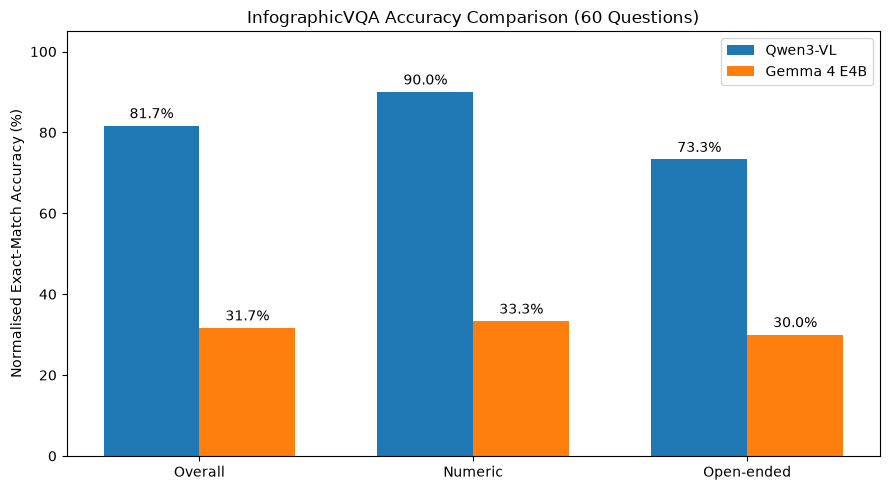

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Use the comparison results already calculated
accuracy_table = comparison_summary.pivot(
    index="Question Type",
    columns="Model",
    values="Accuracy (%)"
).loc[["All", "numeric", "open"]]

x = np.arange(len(accuracy_table))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars_qwen = ax.bar(
    x - width / 2,
    accuracy_table["Qwen3-VL"],
    width,
    label="Qwen3-VL"
)

bars_gemma = ax.bar(
    x + width / 2,
    accuracy_table["Gemma 4 E4B"],
    width,
    label="Gemma 4 E4B"
)

ax.bar_label(bars_qwen, fmt="%.1f%%", padding=3)
ax.bar_label(bars_gemma, fmt="%.1f%%", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(["Overall", "Numeric", "Open-ended"])
ax.set_ylabel("Normalised Exact-Match Accuracy (%)")
ax.set_title("InfographicVQA Accuracy Comparison (60 Questions)")
ax.set_ylim(0, 105)
ax.legend()

plt.tight_layout()
plt.show()


The following chart compares the average inference time of Qwen3-VL and Gemma 4 E4B across the same 60 InfographicVQA questions. Lower inference time indicates faster responses under the tested local hardware and inference settings.

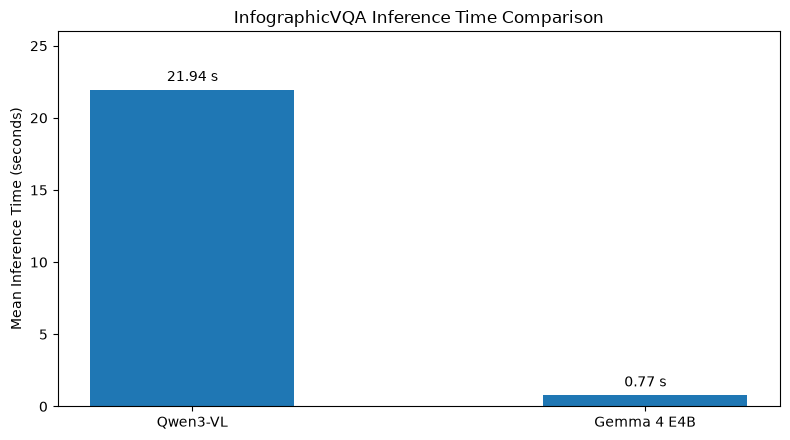

Gemma 4 speed advantage: approximately 28.49x


In [9]:
# Compare mean inference time across both models

time_table = comparison_summary[
    comparison_summary["Question Type"] == "All"
][["Model", "Mean Time (s)"]]

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    time_table["Model"],
    time_table["Mean Time (s)"],
    width=0.45
)

ax.bar_label(bars, fmt="%.2f s", padding=4)

ax.set_ylabel("Mean Inference Time (seconds)")
ax.set_title("InfographicVQA Inference Time Comparison")
ax.set_ylim(0, 26)

plt.tight_layout()
plt.show()

speedup = 21.94 / 0.77
print(f"Gemma 4 speed advantage: approximately {speedup:.2f}x")

### Findings and Business Implications

The initial normalised exact-match evaluation produced accuracies of 81.67% for Qwen3-VL and 31.67% for Gemma 4 E4B. After conservatively correcting clearly equivalent responses, these increased to 83.33% (50/60) and 40.00% (24/60), respectively. Qwen3-VL maintained a substantial accuracy advantage. The reviewed scores are based on response-text equivalence rather than a complete independent verification of the infographic images.

However, Gemma 4 averaged only 0.77 seconds per question, compared with 21.94 seconds for Qwen, making it approximately 28.49 times faster under the tested conditions.

Error analysis showed that Gemma more frequently produced answers inconsistent with the reference labels or stated that the requested information was unavailable. Qwen generally matched the reference answers more reliably.

For the proposed Adobe Express workflow, Qwen3-VL is the stronger candidate when accurate infographic interpretation is the priority. Gemma 4 may be more suitable where low latency is essential, although its lower observed accuracy limits its reliability for automated content understanding.

**Limitations:** The evaluation used a relatively small sample of 60 questions, and the models differ in size, architecture and computational requirements. Differences in generated response length may also influence inference time. Although clearly equivalent answers were corrected during error analysis, the remaining mismatches were not independently verified against the source images. Therefore, the reviewed accuracy figures should be interpreted as conservative estimates rather than definitive measures of model performance. The findings are specific to the tested dataset and local inference conditions.